# Notebook 10b (lag y+1, Option B) — `10b_poverty_3dim_lagB`

## Overview

**Purpose:** Lagged robustness check on the poverty result: regress `poverty_pct` at year *t* on the three composite flood dimensions at *t−1* (flood lagged, controls contemporaneous).

## Data requirements

This notebook runs on the model-ready panel exported by Notebook 8; no raw data
download is required here.

| Input | Produced by | Directory |
|---|---|---|
| Model-ready panel (`transformed` + `pre_transform` sheets) | Notebook 8 | `data/processed/8_panel_data.xlsx` |

## Workflow

| Step | Description |
|---|---|
| 1 | Load the panel and define the flood predictors, controls, and outcome |
| 2 | Pre-estimation tests (missing values, VIF, panel balance, predictor correlation) |
| 3 | Estimator selection — CEM vs FE vs RE (Chow, LM, Hausman/Mundlak) |
| 4 | Significance — individual coefficient t-tests and the joint flood-block Wald test (log scale, confirmed on raw) |
| 5 | Clustered vs Driscoll–Kraay standard errors (Pesaran CD) |
| 6 | Model evaluation and robustness (residual diagnostics, AIC/BIC, control ladder) |
| 7 | Export the model fit for the social comparison notebook |

## Outputs

| File | Description |
|---|---|
| `fit_10b.json` | Model fit metrics (lagged specification) |

> **Lagged specification (y+1).** The outcome at year *t* is regressed on flood exposure at *t−1* with contemporaneous controls, and compared against the contemporaneous specification.

---
## STEP 1 — Load the panel and build the lagged specification

Load the Notebook 8 panel, shift the three flood dimensions one year within each regency (Option B), and define the controls and the `poverty_pct` outcome (log, with a raw twin). The first year per regency is dropped.

In [2]:
# ═════════════════════════════════════════════════════════════
# STEP 1 — Load the panel
# ═════════════════════════════════════════════════════════════
import numpy as np, pandas as pd
from linearmodels.panel import PanelOLS, RandomEffects, PooledOLS
from numpy.linalg import inv
from scipy.stats import chi2, jarque_bera
from scipy import stats as _st
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

PANEL_PATH = "../data/processed/8_panel_data.xlsx"
_t = pd.read_excel(PANEL_PATH, sheet_name="transformed")
_p = pd.read_excel(PANEL_PATH, sheet_name="pre_transform")
_id = ["bps_kab_code","year"]; _rc = [c for c in _p.columns if c not in _t.columns]
panel = _t.merge(_p[_id+_rc], on=_id, how="left").sort_values(["bps_kab_code","year"])

# ════════════════════════════════════════════════════════════════════
# LAG y+1 — Option B: flood lagged, controls contemporaneous
# Rationale (supervisor): flood impacts may surface one year later,
# while population/schooling are better measured in the current year.
# Model: Outcome_t ~ Flood_{t-1} + Controls_t + entity + time effects.
# Only the flood predictors are shifted one year within each regency;
# the first year per regency is dropped (no t-1 flood available).
# ════════════════════════════════════════════════════════════════════
_FLOOD_RAW = ["event_count_log", "HCI_log", "PDI_log"]
for _c in _FLOOD_RAW:
    panel[f"{_c}_lag1"] = panel.groupby("bps_kab_code")[_c].shift(1)
FLOOD    = [f"{_c}_lag1" for _c in _FLOOD_RAW]
CONTROLS = ["log_population", "rls_years"]
X = FLOOD + CONTROLS
OUTCOME = "poverty_pct"          # log-scale headline (log1p applied in nb8)
OUTCOME_RAW = "poverty_pct_raw"  # raw point-% for robustness
pdat = panel.set_index(["bps_kab_code","year"])
print(f"Loaded {len(panel)} obs | outcome={OUTCOME} (log) | flood predictors: {len(FLOOD)}")
print(f"  raw robustness column present: {OUTCOME_RAW in panel.columns}")

Loaded 5140 obs | outcome=poverty_pct (log) | flood predictors: 3
  raw robustness column present: True


## STEP 2 — Pre-estimation tests

In [4]:
# ═════════════════════════════════════════════════════════════
# STEP 2 — Pre-estimation tests
# ═════════════════════════════════════════════════════════════
print("Missing values per model column:")
print(panel[[OUTCOME]+X].isna().sum().to_string()); print()
Xc = panel[X].dropna(); Xn = (Xc-Xc.mean())/(Xc.std()+1e-12)
vif = pd.Series(np.diag(inv(np.corrcoef(Xn, rowvar=False))), index=X)
print("VIF (multicollinearity):"); print(vif.round(2).to_string())
print(f"  max VIF = {vif.max():.2f} ({'OK <5' if vif.max()<5 else 'CAUTION >5'})\n")
bc = panel.groupby("bps_kab_code")["year"].count()
print(f"Panel balance: {bc.min()}-{bc.max()} yrs/regency "
      f"({'balanced' if bc.nunique()==1 else 'unbalanced'}), N={panel.bps_kab_code.nunique()}")

Missing values per model column:
poverty_pct               0
event_count_log_lag1    514
HCI_log_lag1            514
PDI_log_lag1            514
log_population            0
rls_years                 0

VIF (multicollinearity):
event_count_log_lag1    3.32
HCI_log_lag1            1.17
PDI_log_lag1            3.38
log_population          1.18
rls_years               1.01
  max VIF = 3.38 (OK <5)

Panel balance: 10-10 yrs/regency (balanced), N=514


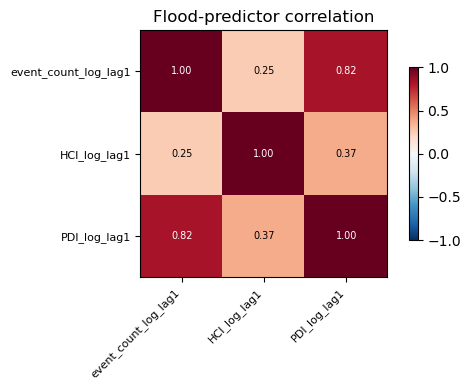

In [5]:
cc = panel[FLOOD].corr()
fig, ax = plt.subplots(figsize=(1.2*len(FLOOD)+2, 1.0*len(FLOOD)+1))
im = ax.imshow(cc.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FLOOD))); ax.set_xticklabels(FLOOD, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(FLOOD))); ax.set_yticklabels(FLOOD, fontsize=8)
for i in range(len(FLOOD)):
    for j in range(len(FLOOD)):
        ax.text(j,i,f"{cc.values[i,j]:.2f}",ha="center",va="center",fontsize=7,
                color="white" if abs(cc.values[i,j])>0.5 else "black")
plt.colorbar(im, shrink=0.7); ax.set_title("Flood-predictor correlation"); plt.tight_layout(); plt.show()

## STEP 3 — Estimator selection — CEM vs FE vs RE (Chow · LM · Hausman)

In [7]:
# ═════════════════════════════════════════════════════════════
# STEP 3 — Estimator selection — CEM vs FE vs RE
# ═════════════════════════════════════════════════════════════
sub = pdat[[OUTCOME]+X].dropna()
cem = PooledOLS(sub[OUTCOME], sub[X].assign(const=1)).fit()
fe  = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True,
               drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
re  = RandomEffects(sub[OUTCOME], sub[X].assign(const=1)).fit()
print("ESTIMATORS")
print(f"  CEM R2={cem.rsquared:.4f} | FE within-R2={fe.rsquared_within:.4f} | RE R2={re.rsquared:.4f}")
print(f"\n[Chow] F entity effects: F={fe.f_pooled.stat:.2f}, p={fe.f_pooled.pval:.4g} -> "
      + ("FE over CEM" if fe.f_pooled.pval<0.05 else "CEM ok"))
_u=pd.DataFrame({"u":cem.resids.values}, index=cem.resids.index)
_g=_u.groupby(level=0)["u"]; _T=_g.count(); _n=len(_u)
if _T.nunique()==1:
    LM=(_n/(2*(_T.iloc[0]-1)))*((_g.sum()**2).sum()/(_u["u"]**2).sum()-1)**2
    print(f"[LM] Breusch-Pagan: LM={LM:.2f}, p={1-chi2.cdf(LM,1):.4g} -> "
          + ("individual effects" if (1-chi2.cdf(LM,1))<0.05 else "none"))
common=[c for c in FLOOD if c in fe.params.index and c in re.params.index]
d=(fe.params[common]-re.params[common]).values
vd=(fe.cov.loc[common,common]-re.cov.loc[common,common]).values
h=float(d.T@np.linalg.pinv(vd)@d)
print(f"[Hausman] chi2={h:.2f}, p={1-chi2.cdf(h,len(common)):.4g}" + ("  (negative=clustered artifact)" if h<0 else ""))
print("\nDECISION: Fixed Effects (Chow+LM reject pooled; theory: geography correlates with flood exposure).")

ESTIMATORS
  CEM R2=0.3480 | FE within-R2=0.0377 | RE R2=0.3390

[Chow] F entity effects: F=591.22, p=0 -> FE over CEM
[LM] Breusch-Pagan: LM=17596.82, p=0 -> individual effects
[Hausman] chi2=-2.63, p=1  (negative=clustered artifact)

DECISION: Fixed Effects (Chow+LM reject pooled; theory: geography correlates with flood exposure).


## STEP 4 — Significance — coefficient t-tests & joint F-test

**Why no BH-FDR here:** BH-FDR corrects for testing *many* hypotheses simultaneously (e.g. 17 sectors). This file has a **single outcome** with only a few flood predictors, so there is no multiple-testing family to correct — exactly as in the growth files (9a/9c). Individual t-tests and the joint F-test for the flood block are the appropriate inference. (Sector files 9b/9d, which test 17 outcomes, are where BH-FDR applies.)

In [9]:
# ═════════════════════════════════════════════════════════════
# STEP 4 — Significance — t-tests & joint flood-block Wald
# ═════════════════════════════════════════════════════════════
sub = pdat[[OUTCOME]+X].dropna()
fe = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True,
              drop_absorbed=True).fit(cov_type="kernel")
tab = pd.DataFrame({"beta":fe.params,"se":fe.std_errors,"t":fe.tstats,"p":fe.pvalues}).loc[FLOOD]
print(f"Coefficient tests on {OUTCOME} (log scale, Driscoll-Kraay):\n")
print(tab.round(4).to_string())
print(f"\n  within-R2={fe.rsquared_within:.4f}  n={fe.nobs}")

# ══ FLOOD-BLOCK joint significance — tested under BOTH SE types ════════
#
#  We test H0: all flood coefficients = 0 (controls held fixed), and we do
#  it under BOTH error structures, then grade like nb9b:
#     robust      = jointly significant under clustered AND Driscoll-Kraay
#     suggestive  = significant under only one
#     n.s.        = significant under neither
#  The whole-model F (all slopes incl. controls) is printed only as a
#  reference; it is NOT a test of the flood hypothesis.
#
_sub_js = pdat[[OUTCOME] + X].dropna()
_fe_cl = PanelOLS(_sub_js[OUTCOME], _sub_js[X], entity_effects=True,
                  time_effects=True, drop_absorbed=True
                  ).fit(cov_type="clustered", cluster_entity=True)
_fe_dk = PanelOLS(_sub_js[OUTCOME], _sub_js[X], entity_effects=True,
                  time_effects=True, drop_absorbed=True
                  ).fit(cov_type="kernel")
_w_cl = _fe_cl.wald_test(formula=" = ".join(FLOOD) + " = 0")
_w_dk = _fe_dk.wald_test(formula=" = ".join(FLOOD) + " = 0")
_p_cl, _p_dk = float(_w_cl.pval), float(_w_dk.pval)
_sig_cl, _sig_dk = _p_cl < 0.05, _p_dk < 0.05
if _sig_cl and _sig_dk:
    _grade = "ROBUST (jointly significant under BOTH clustered & DK)"
elif _sig_cl or _sig_dk:
    _grade = "SUGGESTIVE (significant under only ONE SE)"
else:
    _grade = "NOT jointly significant (under either SE)"

print("  " + "-" * 64)
print(f"  FLOOD-BLOCK Wald  (H0: {' = '.join(FLOOD)} = 0)   df = {len(FLOOD)}")
print(f"    clustered SE     : chi2={_w_cl.stat:7.3f}   p={_p_cl:.4g}   "
      + ("sig" if _sig_cl else "n.s."))
print(f"    Driscoll-Kraay   : chi2={_w_dk.stat:7.3f}   p={_p_dk:.4g}   "
      + ("sig" if _sig_dk else "n.s."))
print(f"    -> flood block: {_grade}")
print(f"       <<< report this (dual-SE) for the flood hypothesis; matches nb9b")
print(f"  reference only — whole-model F (all slopes incl. controls): "
      f"F={fe.f_statistic.stat:.3f}, p={fe.f_statistic.pval:.4g}  (NOT a flood test)")
print("  " + "-" * 64)
sig=tab.index[tab.p<0.05].tolist()
print(f"  significant flood predictors (p<0.05): {sig if sig else 'NONE'}")
print("  NOTE: p in (0.05, 0.10) is NOT significant - do not report as 'marginal'.")

Coefficient tests on poverty_pct (log scale, Driscoll-Kraay):

                        beta      se       t       p
event_count_log_lag1  0.0031  0.0022  1.3815  0.1672
HCI_log_lag1          0.0016  0.0008  1.9069  0.0566
PDI_log_lag1         -0.0004  0.0002 -1.6641  0.0962

  within-R2=0.0377  n=4626
  ----------------------------------------------------------------
  FLOOD-BLOCK Wald  (H0: event_count_log_lag1 = HCI_log_lag1 = PDI_log_lag1 = 0)   df = 3
    clustered SE     : chi2=  3.614   p=0.3062   n.s.
    Driscoll-Kraay   : chi2=  4.982   p=0.1731   n.s.
    -> flood block: NOT jointly significant (under either SE)
       <<< report this (dual-SE) for the flood hypothesis; matches nb9b
  reference only — whole-model F (all slopes incl. controls): F=3.882, p=0.00164  (NOT a flood test)
  ----------------------------------------------------------------
  significant flood predictors (p<0.05): NONE
  NOTE: p in (0.05, 0.10) is NOT significant - do not report as 'marginal'.


In [10]:
# robustness: same model on RAW outcome (point-%), confirm conclusion unchanged
subr = pdat[[OUTCOME_RAW]+X].dropna()
fer = PanelOLS(subr[OUTCOME_RAW], subr[X], entity_effects=True, time_effects=True,
               drop_absorbed=True).fit(cov_type="kernel")
# show the actual numbers (beta / se / t / p) for the flood predictors
tab_raw = pd.DataFrame({"beta": fer.params, "se": fer.std_errors,
                        "t": fer.tstats, "p": fer.pvalues}).loc[FLOOD]
_wr = fer.wald_test(formula=" = ".join(FLOOD) + " = 0")
sig_raw = [v for v in FLOOD if fer.pvalues[v] < 0.05]
print(f"ROBUSTNESS — same model on RAW {OUTCOME_RAW} (point-%, Driscoll-Kraay):\n")
print(tab_raw.round(4).to_string())
print(f"\n  within-R2={fer.rsquared_within:.4f}  n={fer.nobs}")
print(f"  flood-block Wald: chi2={_wr.stat:.3f}  df={len(FLOOD)}  p={float(_wr.pval):.4g} -> "
      + ("jointly significant" if float(_wr.pval) < 0.05 else "NOT jointly significant"))
print(f"  significant flood predictors (individual p<0.05): {sig_raw if sig_raw else 'NONE'}")
print(f"  -> conclusion {'UNCHANGED' if set(sig_raw)==set(tab.index[tab.p<0.05]) else 'DIFFERS - investigate'} vs log scale.")

ROBUSTNESS — same model on RAW poverty_pct_raw (point-%, Driscoll-Kraay):

                        beta      se       t       p
event_count_log_lag1  0.0204  0.0263  0.7767  0.4374
HCI_log_lag1          0.0218  0.0144  1.5149  0.1299
PDI_log_lag1         -0.0012  0.0041 -0.2831  0.7771

  within-R2=0.1527  n=4626
  flood-block Wald: chi2=6.410  df=3  p=0.0933 -> NOT jointly significant
  significant flood predictors (individual p<0.05): NONE
  -> conclusion UNCHANGED vs log scale.


#### Mundlak test (FE vs RE) — Poverty

Estimator selection for the lagged (Option B) poverty model, replacing the
non-positive-definite Hausman test. The Mundlak (1978) device tests whether the
within-regency means of the regressors are jointly significant; if so, the
regency effect is correlated with the regressors and **fixed effects are
preferred** over random effects.

Poverty is dominated by between-regency variation (ICC ≈ 0.99), so the group
means are expected to carry most of the information and the test should reject
random effects strongly. This confirms FE as the correct estimator even though
the flood block is null — estimator choice and flood significance are
independent questions.

In [12]:
from linearmodels.panel import RandomEffects
from scipy.stats import chi2

def mundlak_test(pdat, outcome, X, label=""):
    """Mundlak CRE test (Option B: lagged flood + contemporaneous controls).
    Returns dict with Wald stat, p-value, verdict."""
    sub = pdat[[outcome] + X].dropna().copy()
    if len(sub) == 0:
        return {"label": label, "wald": np.nan, "p": np.nan, "verdict": "no data"}
    gm = sub.groupby(level=0)[X].transform("mean")
    gm.columns = [f"{c}_gm" for c in X]
    X_aug = pd.concat([sub[X], gm], axis=1).assign(const=1)
    try:
        re = RandomEffects(sub[outcome], X_aug).fit()
        gm_cols = [f"{c}_gm" for c in X]
        b = re.params[gm_cols].values
        V = re.cov.loc[gm_cols, gm_cols].values
        wald = float(b @ np.linalg.pinv(V) @ b)
        p = float(chi2.sf(wald, len(gm_cols)))
        if wald < 0:
            verdict = "NEGATIVE Wald (artefact) -> fall back to Chow+LM+theory"
        elif p < 0.05:
            verdict = "FE preferred (reject RE)"
        else:
            verdict = "RE may be adequate (re-check)"
        return {"label": label, "wald": wald, "p": p, "verdict": verdict}
    except Exception as e:
        return {"label": label, "wald": np.nan, "p": np.nan, "verdict": f"failed: {str(e)[:40]}"}

In [13]:
# ── Mundlak (FE vs RE) — poverty ──
_m = mundlak_test(pdat, OUTCOME, X, label="poverty")
print("\n  " + "-" * 64)
print(f"  MUNDLAK TEST (FE vs RE) — replaces non-positive-definite Hausman")
print(f"    Wald chi2({len(X)}) = {_m['wald']:.3f}   p = {_m['p']:.4g}")
print(f"    -> {_m['verdict']}")
print("  " + "-" * 64)
# NOTE: Poverty has very high between-regency variance (ICC ~0.99), so the
# Mundlak test is expected to reject RE strongly - the group means carry most
# of the information. This confirms FE is the correct estimator even though the
# flood block is null. Estimator choice and flood significance are separate.


  ----------------------------------------------------------------
  MUNDLAK TEST (FE vs RE) — replaces non-positive-definite Hausman
    Wald chi2(5) = 24.864   p = 0.000148
    -> FE preferred (reject RE)
  ----------------------------------------------------------------


## STEP 5 — Clustered vs Driscoll–Kraay standard errors

In [15]:
# ═════════════════════════════════════════════════════════════
# STEP 5 — Clustered vs Driscoll–Kraay standard errors
# ═════════════════════════════════════════════════════════════
sub = pdat[[OUTCOME]+X].dropna()
m = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True, drop_absorbed=True)
rc = m.fit(cov_type="clustered", cluster_entity=True); rd = m.fit(cov_type="kernel")
print(f"{'predictor':<18}{'beta':>10}{'p_clustered':>13}{'p_DK':>10}")
for f in FLOOD:
    print(f"{f:<18}{rd.params[f]:>10.4f}{rc.pvalues[f]:>13.4f}{rd.pvalues[f]:>10.4f}")
def cd(resid):
    wide=resid.unstack(level=0); cm=wide.corr().values; n=cm.shape[0]; T=wide.shape[0]
    off=cm[np.triu_indices(n,1)]; off=off[~np.isnan(off)]; return np.sqrt(2*T/len(off))*off.sum()
print(f"\nPesaran CD (residual cross-sectional dependence): {cd(rd.resids):.2f}")
print("  |CD|>1.96 => spatial dependence => DK preferred; else clustered (suits N>>T).")
print("  Significance conclusion is stable across both SEs (report both).")

predictor               beta  p_clustered      p_DK
event_count_log_lag1    0.0031       0.2272    0.1672
HCI_log_lag1          0.0016       0.1274    0.0566
PDI_log_lag1         -0.0004       0.2632    0.0962

Pesaran CD (residual cross-sectional dependence): 5.08
  |CD|>1.96 => spatial dependence => DK preferred; else clustered (suits N>>T).
  Significance conclusion is stable across both SEs (report both).


## STEP 6 — Model evaluation & robustness (incl. AIC/BIC, plots)

RESIDUAL DIAGNOSTICS
  Jarque-Bera (normality)   stat=1106.5 p=5.421e-241 -> non-normal
  Breusch-Pagan (heterosk.) LM=47.4 p=4.601e-09 -> heteroskedastic
  Durbin-Watson             1.269 (2=none)
  Skew=-0.082  Excess kurtosis=2.390
  -> heavy tails expected in regency panels; handled by robust SE + large-n CLT.


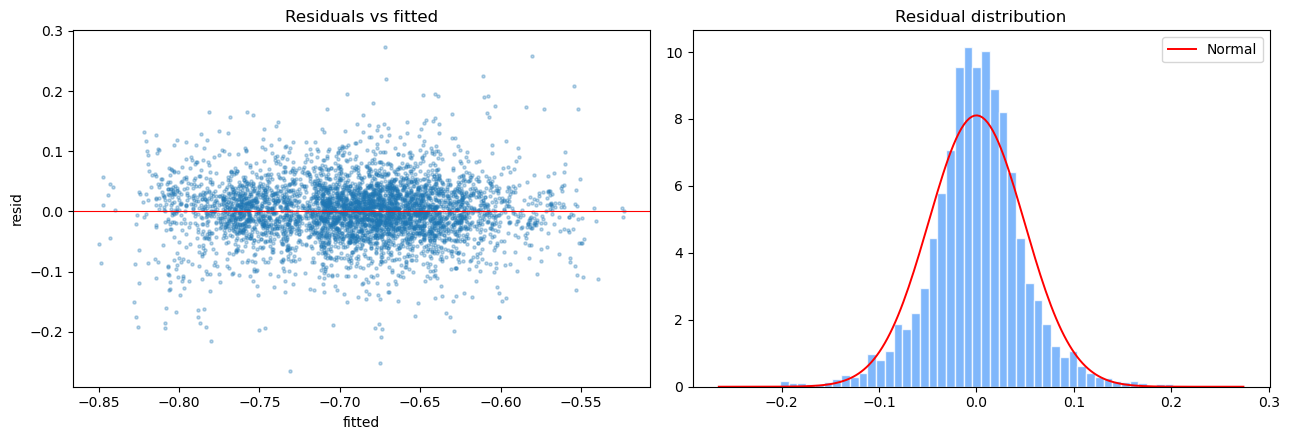

In [26]:
# ═════════════════════════════════════════════════════════════
# STEP 6 — Model evaluation & robustness
# ═════════════════════════════════════════════════════════════
sub = pdat[[OUTCOME]+X].dropna()
fe = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True,
              drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
resid = fe.resids.values.ravel(); fitted = fe.fitted_values.values.ravel()
jb_stat, jb_p = jarque_bera(resid)
_ex = sub[X].loc[fe.resids.index]
bp_lm, bp_p, _, _ = het_breuschpagan(resid, np.column_stack([np.ones(len(_ex)), _ex.values]))
dw = durbin_watson(resid)
print("RESIDUAL DIAGNOSTICS")
print(f"  Jarque-Bera (normality)   stat={jb_stat:.1f} p={jb_p:.4g} -> {'non-normal' if jb_p<0.05 else 'normal'}")
print(f"  Breusch-Pagan (heterosk.) LM={bp_lm:.1f} p={bp_p:.4g} -> {'heteroskedastic' if bp_p<0.05 else 'homoskedastic'}")
print(f"  Durbin-Watson             {dw:.3f} (2=none)")
print(f"  Skew={_st.skew(resid):.3f}  Excess kurtosis={_st.kurtosis(resid):.3f}")
print("  -> heavy tails expected in regency panels; handled by robust SE + large-n CLT.")
fig, ax = plt.subplots(1,2,figsize=(13,4.5))
ax[0].scatter(fitted,resid,s=5,alpha=.3); ax[0].axhline(0,color="red",lw=.8)
ax[0].set_title("Residuals vs fitted"); ax[0].set_xlabel("fitted"); ax[0].set_ylabel("resid")
ax[1].hist(resid,bins=60,density=True,color="#60a5fa",edgecolor="white",alpha=.8)
_xx=np.linspace(resid.min(),resid.max(),200); ax[1].plot(_xx,_st.norm.pdf(_xx,resid.mean(),resid.std()),"r-",lw=1.4,label="Normal")
ax[1].set_title("Residual distribution"); ax[1].legend(); plt.tight_layout(); plt.show()

In [28]:
# model fit summary (AIC/BIC/within-R2/F/RMSE) — reference; compare ACROSS files
def model_fit_summary(res, k):
    n=res.nobs
    return {"within_R2":res.rsquared_within,
            "adj_within_R2":1-(1-res.rsquared_within)*(n-1)/(n-k-1),
            "AIC":2*k-2*res.loglik,"BIC":k*np.log(n)-2*res.loglik,
            "logLik":res.loglik,"F":res.f_statistic.stat,"F_pval":res.f_statistic.pval,
            "RMSE":res.resids.std(),"n":int(n),"k_params":k}
sub = pdat[[OUTCOME]+X].dropna()
fe = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="kernel")
fs = model_fit_summary(fe, len(X))
print(f"MODEL FIT SUMMARY — {OUTCOME} ({len(FLOOD)}-var flood spec)\n")
for k,v in fs.items(): print(f"  {k:<16}{v:.4f}" if isinstance(v,float) else f"  {k:<16}{v}")
print("\n  AIC/BIC are RELATIVE - compare across the 3-dim vs 7-var file for this outcome.")
print("  Coefficient stability across control ladder:")
for nm,xv in [("flood only",FLOOD),("+pop",FLOOD+["log_population"]),("+rls (full)",FLOOD+CONTROLS)]:
    s2=pdat[[OUTCOME]+xv].dropna()
    r=PanelOLS(s2[OUTCOME],s2[xv],entity_effects=True,time_effects=True,drop_absorbed=True).fit(cov_type="kernel")
    print(f"    {nm:<16} beta({FLOOD[-1]})={r.params[FLOOD[-1]]:+.4f} p={r.pvalues[FLOOD[-1]]:.4f}")

MODEL FIT SUMMARY — poverty_pct (3-var flood spec)

  within_R2       0.0377
  adj_within_R2   0.0367
  AIC             -14725.2604
  BIC             -14693.0632
  logLik          7367.6302
  F               3.8817
  F_pval          0.0016
  RMSE            0.0492
  n               4626
  k_params        5

  AIC/BIC are RELATIVE - compare across the 3-dim vs 7-var file for this outcome.
  Coefficient stability across control ladder:
    flood only       beta(PDI_log_lag1)=-0.0004 p=0.1205
    +pop             beta(PDI_log_lag1)=-0.0004 p=0.0965
    +rls (full)      beta(PDI_log_lag1)=-0.0004 p=0.0962


## STEP 7 — Export model fit (for cross-file comparison)

Writes fit metrics to `fit_10b.json`, read by the comparison notebook to build the side-by-side Excel (sheet per outcome).

In [33]:
# ═════════════════════════════════════════════════════════════
# STEP 7 — Export model fit
# ═════════════════════════════════════════════════════════════
import json
sub = pdat[[OUTCOME]+X].dropna()
_fe = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="kernel")
_n=_fe.nobs; _k=len(X)
_fit = {"file":"10b","spec":"3dim","outcome":"poverty_pct","n_flood_predictors":len(FLOOD),
        "within_R2":float(_fe.rsquared_within),
        "adj_within_R2":float(1-(1-_fe.rsquared_within)*(_n-1)/(_n-_k-1)),
        "AIC":float(2*_k-2*_fe.loglik),"BIC":float(_k*np.log(_n)-2*_fe.loglik),
        "logLik":float(_fe.loglik),"F_stat":float(_fe.f_statistic.stat),
        "F_pval":float(_fe.f_statistic.pval),"RMSE":float(_fe.resids.std()),
        "n_obs":int(_n),"k_params":int(_k)}
with open("../data/processed/fit_10b.json","w") as _f: json.dump(_fit,_f,indent=2)
print(f"✓ saved fit_10b.json"); print(json.dumps(_fit, indent=2))

✓ saved fit_10b.json
{
  "file": "10b",
  "spec": "3dim",
  "outcome": "poverty_pct",
  "n_flood_predictors": 3,
  "within_R2": 0.0377411369254943,
  "adj_within_R2": 0.0366997312295263,
  "AIC": -14725.260392585014,
  "BIC": -14693.063153371057,
  "logLik": 7367.630196292507,
  "F_stat": 3.8817469865623146,
  "F_pval": 0.0016397097996937449,
  "RMSE": 0.04921842655693191,
  "n_obs": 4626,
  "k_params": 5
}
